In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter
from sklearn.tree import DecisionTreeClassifier

train = np.load("../Data/X_train.npy.npz")
X_train = train["X_train"]
y_train = train["y_train"]

valid = np.load("../Data/X_valid.npy.npz")
X_valid = valid["X_valid"]
y_valid = valid["y_valid"]

test = np.load("../Data/X_test.npy.npz")
X_test = test["X_test"]
y_test = test["y_test"]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (240, 4096) (240,)
Validation: (80, 4096) (80,)
Test: (80, 4096) (80,)


In [ ]:
#Q2(a):

In [5]:
# Initialize sample data
X_sample = np.array([[1], [2], [3], [4], [5], [6]])
y_sample = np.array(["A", "A", "B", "B", "C", "C"])

# Initialize equal sample weights
weights = np.ones(len(y_sample)) / len(y_sample)

# Get the weak learner's predictions
predictions = np.array(["A", "A", "B", "C", "C", "B"])

incorrect = predictions != y_sample

# Calculate weighted error
weighted_error = weights[incorrect].sum()

# Calculate the SAMME learner weight
K = len(np.unique(y_sample))

alpha = (
    np.log((1 - weighted_error) / weighted_error)
    + np.log(K - 1)
)

# Update the weights of misclassified samples
updated_weights = weights.copy()
updated_weights[incorrect] *= np.exp(alpha)

# Normalize the weights so they sum to 1
updated_weights /= updated_weights.sum()

In [6]:
round_log = pd.DataFrame({
    "Sample": np.arange(1, len(y_sample) + 1),
    "True Class": y_sample,
    "Prediction": predictions,
    "Correct": ~incorrect,
    "Initial Weight": weights,
    "Updated Weight": updated_weights
})

print(f"Weighted error: {weighted_error:.6f}")
print(f"Alpha: {alpha:.6f}")
print(f"Sum of updated weights: {updated_weights.sum():.6f}")

round_log

Weighted error: 0.333333
Alpha: 1.386294
Sum of updated weights: 1.000000


,Sample,True Class,Prediction,Correct,Initial Weight,Updated Weight
0,1,A,A,True,0.166667,0.083333
1,2,A,A,True,0.166667,0.083333
2,3,B,B,True,0.166667,0.083333
3,4,B,C,False,0.166667,0.333333
4,5,C,C,True,0.166667,0.083333
5,6,C,B,False,0.166667,0.333333


In [58]:
#Q2(b)
def train_samme(X, y, max_depth, n_rounds, random_state=26001):
    """
    Train a multiclass SAMME boosting ensemble.

    Returns:
        Dictionary containing trained trees, SAMME weights (alphas),
        and per-round diagnostics.
    """
    X = np.asarray(X)
    y = np.asarray(y)

    n_samples = len(y)
    classes = np.unique(y)
    K = len(classes)

    if K < 2:
        raise ValueError("SAMME requires at least two classes.")
    if n_samples == 0:
        raise ValueError("Training data cannot be empty.")
    if len(X) != n_samples:
        raise ValueError("X and y must contain the same number of samples.")
    if n_rounds < 1:
        raise ValueError("n_rounds must be at least 1.")

    # Initialize equal weights for all training samples
    weights = np.full(n_samples, 1.0 / n_samples)
    rng = np.random.default_rng(random_state)

    trees = []
    alphas = []
    weighted_errors = []
    max_sample_weights = []
    top10_weight_sums = []

    random_error_threshold = 1.0 - 1.0 / K

    for t in range(n_rounds):
        tree = DecisionTreeClassifier(
            max_depth=max_depth,
            random_state=int(rng.integers(0, 2**31 - 1))
        )

        # Train the weak learner using current sample weights
        tree.fit(X, y, sample_weight=weights)
        predictions = tree.predict(X)

        incorrect = predictions != y
        weighted_error = float(weights[incorrect].sum())

        # Stop if the learner is no better than random guessing
        if weighted_error >= random_error_threshold:
            break

        # Record diagnostics for the accepted learner
        weighted_errors.append(weighted_error)
        max_sample_weights.append(float(weights.max()))
        top10_weight_sums.append(
            float(np.sort(weights)[-min(10, n_samples):].sum())
        )

        trees.append(tree)

        # Handle a perfect learner with a finite alpha
        if weighted_error <= 1e-12:
            alpha_t = (
                np.log((1.0 - 1e-12) / 1e-12)
                + np.log(K - 1)
            )
            alphas.append(float(alpha_t))
            break

        # Calculate the SAMME multiclass learner weight
        alpha_t = (
            np.log((1.0 - weighted_error) / weighted_error)
            + np.log(K - 1)
        )
        alphas.append(float(alpha_t))

        # Increase weights of misclassified samples
        weights[incorrect] *= np.exp(alpha_t)

        # Normalize sample weights
        weights /= weights.sum()

    return {
        "trees": trees,
        "alphas": alphas,
        "weighted_errors": weighted_errors,
        "max_sample_weights": max_sample_weights,
        "top10_weight_sums": top10_weight_sums,
        "final_sample_weights": weights.copy()
    }

In [59]:
def predict_samme(model, X):
    """
    Predict classes using SAMME's weighted multiclass voting rule.
    """
    X = np.asarray(X)

    trees = model["trees"]
    alphas = model["alphas"]

    if not trees:
        raise ValueError(
            "SAMME trained no weak learner. "
            "Check the weighted error and training data."
        )

    classes = trees[0].classes_
    class_score = np.zeros(
        (len(X), len(classes)),
        dtype=float
    )

    for tree, alpha in zip(trees, alphas):
        predictions = tree.predict(X)

        for class_index, class_label in enumerate(classes):
            class_score[:, class_index] += (
                alpha * (predictions == class_label)
            )

    return classes[np.argmax(class_score, axis=1)]

In [60]:
def predict_samme_confidence(model, X):
    """
    Return the winning class's fraction of the total weighted vote.
    This is a confidence-like score, not a calibrated probability.
    """
    X = np.asarray(X)

    trees = model["trees"]
    alphas = model["alphas"]

    if not trees:
        raise ValueError(
            "SAMME trained no weak learner. "
            "Check the weighted error and training data."
        )

    classes = trees[0].classes_
    class_score = np.zeros(
        (len(X), len(classes)),
        dtype=float
    )

    for tree, alpha in zip(trees, alphas):
        predictions = tree.predict(X)

        for class_index, class_label in enumerate(classes):
            class_score[:, class_index] += (
                alpha * (predictions == class_label)
            )

    total_alpha = np.sum(alphas)

    if total_alpha <= 0:
        raise ValueError("The total learner weight must be positive.")

    return class_score.max(axis=1) / total_alpha

In [61]:
max_depths = [1, 2, 3, 4]
n_rounds = [10, 25, 50, 100]

boosting_results = []

for max_depth in max_depths:
    for n_round in n_rounds:
        samme = train_samme(
            X_train,
            y_train,
            max_depth,
            n_round
        )

        predictions = predict_samme(samme, X_valid)
        valid_acc = np.mean(predictions == y_valid)

        boosting_results.append({
            "max_depth": max_depth,
            "n_round": n_round,
            "val_acc": valid_acc,
            "n_learners": len(samme["trees"])
        })

In [62]:
results_df = pd.DataFrame(boosting_results)
results_df

,max_depth,n_round,val_acc,n_learners
0,1,10,0.0375,10
1,1,25,0.0875,25
2,1,50,0.1125,50
3,1,100,0.1625,100
4,2,10,0.1000,10
5,2,25,0.1625,25
6,2,50,0.2000,50
7,2,100,0.2250,100
8,3,10,0.1875,10
9,3,25,0.1500,25


In [11]:
# Selected Parameters
MAX_DEPTH = 4
N_ROUNDS = 100

# Training the required model
boostingModel = train_samme(
    X=X_train,
    y=y_train,
    max_depth=MAX_DEPTH,
    n_rounds=N_ROUNDS
)

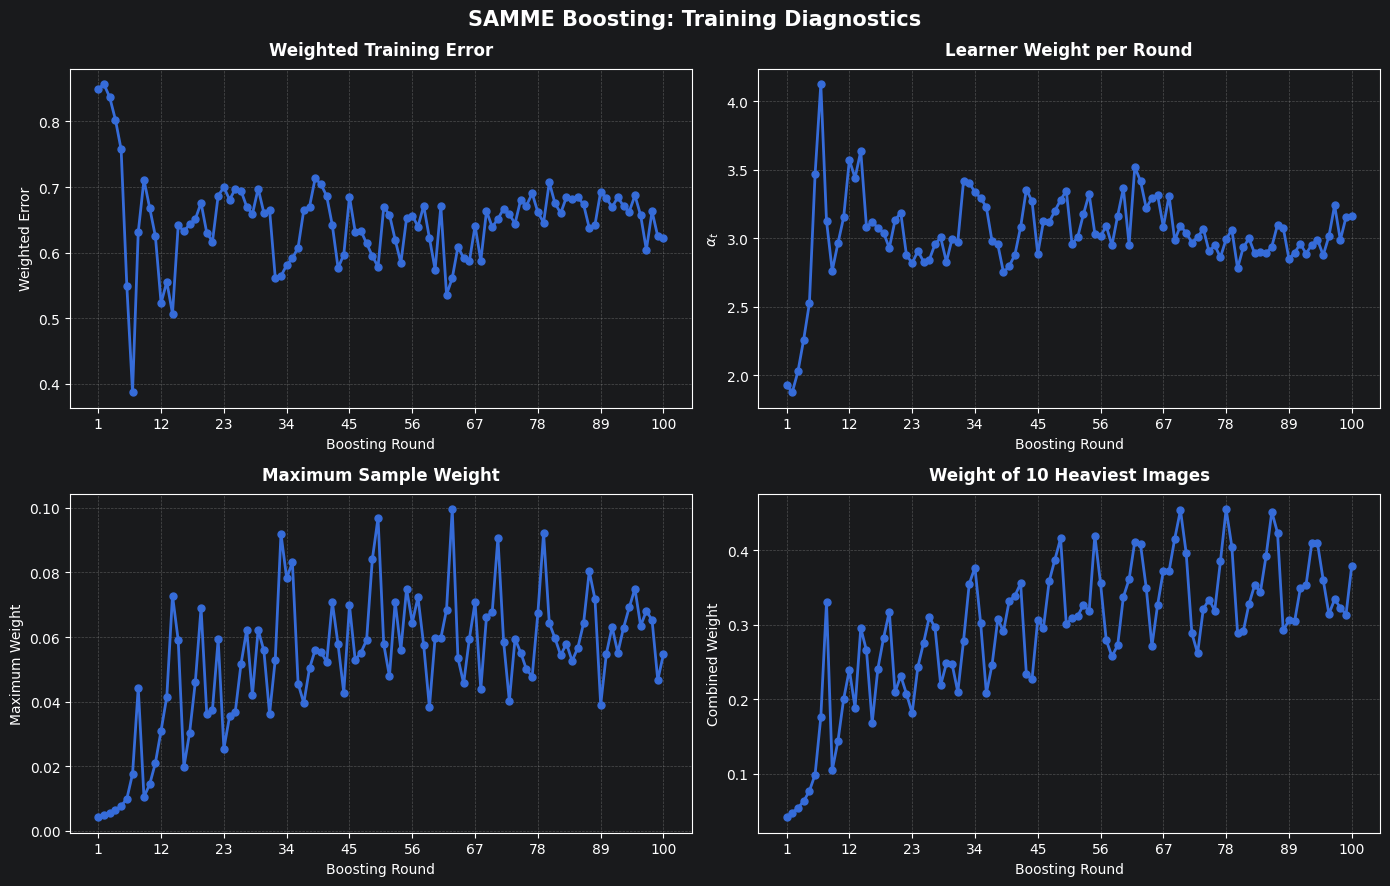

In [12]:
rounds = np.arange(1, len(boostingModel["trees"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

plots = [
    (
        boostingModel["weighted_errors"],
        "Weighted Training Error",
        "Weighted Error"
    ),
    (
        boostingModel["alphas"],
        "Learner Weight per Round",
        r"$\alpha_t$"
    ),
    (
        boostingModel["max_sample_weights"],
        "Maximum Sample Weight",
        "Maximum Weight"
    ),
    (
        boostingModel["top10_weight_sums"],
        "Weight of 10 Heaviest Images",
        "Combined Weight"
    )
]

for ax, (values, title, ylabel) in zip(axes.flat, plots):
    x = np.arange(1, len(values) + 1)

    ax.plot(
        x,
        values,
        marker="o",
        markersize=5,
        linewidth=2
    )

    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Boosting Round", fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_xticks(x if len(x) <= 25 else np.linspace(
        x[0], x[-1], 10, dtype=int
    ))
    ax.grid(True, linestyle="--", alpha=0.35)

fig.suptitle(
    "SAMME Boosting: Training Diagnostics",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [13]:
#Q2(c)

In [76]:
from common.Bagging import Bagging

In [77]:
comparison_results = []

for B in [25, 50, 100]:
    # Train bagging ensemble
    start = perf_counter()

    bagged = bagging(
        X_train,
        y_train,
        B,
        rng=np.random.default_rng(26001)
    )

    bagging_time = perf_counter() - start
    bagged_trees = bagged["trees"]

    # Train SAMME boosting ensemble
    start = perf_counter()

    boosted = train_samme(
        X_train,
        y_train,
        max_depth=MAX_DEPTH,
        n_rounds=B,
        random_state=26001
    )

    boosting_time = perf_counter() - start

    # Evaluate both models on all three splits
    for name, model_trees, predict_fn, train_time in [
        ("Bagging", bagged_trees, predict_bagging, bagging_time),
        ("SAMME", boosted, predict_samme, boosting_time)
    ]:

        def predict_current(X):
            if name == "Bagging":
                return predict_fn(model_trees, X)

            return predict_fn(model_trees, X)

        comparison_results.append({
            "Model": name,
            "Learners requested": B,
            "Learners trained": (
                len(model_trees)
                if name == "Bagging"
                else len(model_trees["trees"])
            ),
            "Train accuracy": np.mean(
                predict_current(X_train) == y_train
            ),
            "Validation accuracy": np.mean(
                predict_current(X_valid) == y_valid
            ),
            "Clean test accuracy": np.mean(
                predict_current(X_test) == y_test
            ),
            "Training time (s)": train_time
        })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Model,Learners requested,Learners trained,Train accuracy,Validation accuracy,Clean test accuracy,Training time (s)
0,Bagging,25,25,1.000000,0.8500,0.7250,49.177626
1,SAMME,25,25,0.354167,0.2125,0.1375,13.085197
2,Bagging,50,50,1.000000,0.8875,0.8250,96.999691
3,SAMME,50,50,0.741667,0.3625,0.3250,27.476132
4,Bagging,100,100,1.000000,0.8750,0.8500,158.848167
5,SAMME,100,100,0.866667,0.3125,0.3250,44.105477


Training image index: 71
True identity: 11
Final sample weight: 0.07529904288081882


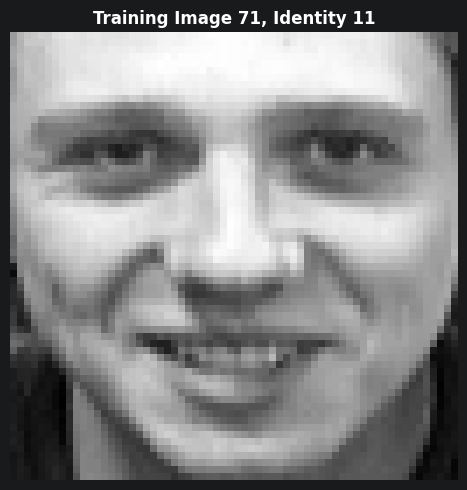

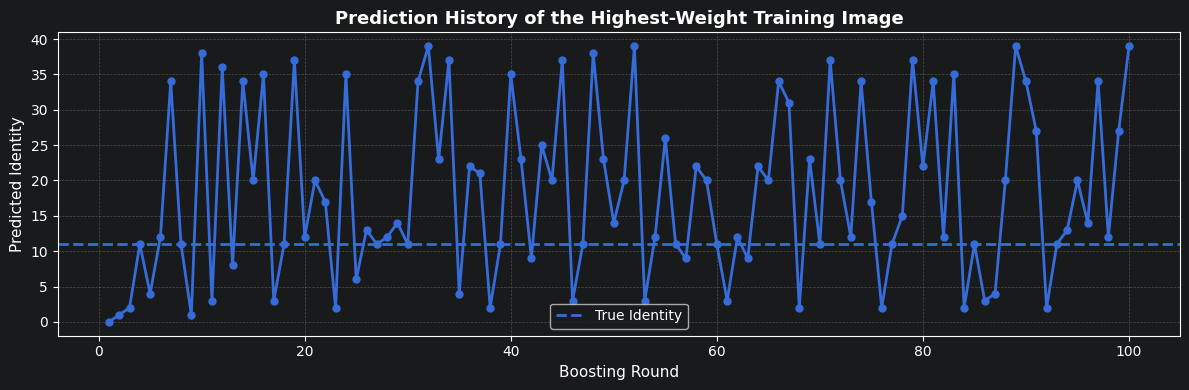

In [78]:
final_weights = boostingModel["final_sample_weights"]
idx = np.argmax(final_weights)

print("Training image index:", idx)
print("True identity:", y_train[idx])
print("Final sample weight:", final_weights[idx])

# Display the highest-weight training image
plt.figure(figsize=(5, 5))

plt.imshow(
    X_train[idx].reshape(64, 64),
    cmap="gray"
)

plt.title(
    f"Training Image {idx}, Identity {y_train[idx]}",
    fontsize=12,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()
plt.show()


# Track how successive weak learners classify this image
history = [
    tree.predict(X_train[idx:idx + 1])[0]
    for tree in boostingModel["trees"]
]

# Plot prediction history
plt.figure(figsize=(12, 4))

plt.plot(
    range(1, len(history) + 1),
    history,
    marker="o",
    markersize=5,
    linewidth=2
)

plt.axhline(
    y_train[idx],
    linestyle="--",
    linewidth=2,
    label="True Identity"
)

plt.xlabel("Boosting Round", fontsize=11)
plt.ylabel("Predicted Identity", fontsize=11)

plt.title(
    "Prediction History of the Highest-Weight Training Image",
    fontsize=13,
    fontweight="bold"
)

plt.grid(True, linestyle="--", alpha=0.35)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
#Q2(c)

In [82]:
# Saving model to local dir ./Models
joblib.dump(boostingModel, 'Models/boostingModel.joblib')

# Save configuration metadata for reproducibility
config = {
    "baseline_max_depth": None,
    "baseline_min_samples_leaf": 2,
    "bagging_max_depth": None,
    "bagging_min_samples_leaf": 2,
    "bagging_n_estimators": 50,
    "boosting_max_depth": 4,
    "boosting_n_rounds": 100,
    "random_seed": 26001
}

joblib.dump(config, "Models/model_config.joblib")

['Models/model_config.joblib']

In [69]:
# Create a copy of the test images and reshape them to 64 × 64
X_masked_test = X_test.reshape(-1, 64, 64).copy()

# Mask the central region of each image
X_masked_test[:, 24:40, 24:40] = 0

# Flatten the images back to 4096 features
X_masked_test = X_masked_test.reshape(-1, 4096)

# Display the resulting shape
X_masked_test.shape

(80, 4096)

In [79]:
base_clean_accuracy = baselineModel.score(X_test, y_test)

base_clean_confidence = (
    baselineModel.predict_proba(X_test)
    .max(axis=1)
    .mean()
)

bagged_clean_preds = predict_bagging(final_bagged_trees, X_test)
bagged_clean_accuracy = np.mean(bagged_clean_preds == y_test)

bagged_clean_confidence = bagging_confidence(
    final_bagged_trees, X_test
).mean()

base_masked_accuracy = baselineModel.score(X_masked_test, y_test)

base_masked_confidence = (
    baselineModel.predict_proba(X_masked_test)
    .max(axis=1)
    .mean()
)

bagged_masked_preds = predict_bagging(
    final_bagged_trees, X_masked_test
)
bagged_masked_accuracy = np.mean(bagged_masked_preds == y_test)

bagged_masked_confidence = bagging_confidence(
    final_bagged_trees, X_masked_test
).mean()

In [80]:
baseline_clean_accuracy = base_clean_accuracy
baseline_clean_confidence = base_clean_confidence

bagging_clean_accuracy = bagged_clean_accuracy
bagging_clean_confidence = bagged_clean_confidence

boosting_clean_accuracy = np.mean(predict_samme(boostingModel, X_test) == y_test)
boosting_clean_confidence = np.mean(predict_samme_confidence(boostingModel, X_test))

# Masked test set
baseline_masked_accuracy = base_masked_accuracy
baseline_masked_confidence = base_masked_confidence

bagging_masked_accuracy = bagged_masked_accuracy
bagging_masked_confidence = bagged_masked_confidence

boosting_masked_accuracy = np.mean(predict_samme(boostingModel, X_masked_test) == y_test)
boosting_masked_confidence = np.mean(predict_samme_confidence(boostingModel, X_masked_test))

# Results table
final_comparison_df = pd.DataFrame({
    "Model": ["Single Tree", "Bagging (B=50)", "SAMME AdaBoost"],
    "Clean Accuracy": [base_clean_accuracy, bagged_clean_accuracy, boosting_clean_accuracy],
    "Clean Mean Confidence": [
        base_clean_confidence, bagged_clean_confidence, boosting_clean_confidence
    ],
    "Masked Accuracy": [base_masked_accuracy, bagged_masked_accuracy, boosting_masked_accuracy],
    "Masked Mean Confidence": [
        base_masked_confidence, bagged_masked_confidence, boosting_masked_confidence
    ]
})

final_comparison_df

,Model,Clean Accuracy,Clean Mean Confidence,Masked Accuracy,Masked Mean Confidence
0,Single Tree,0.5625,0.987500,0.3625,0.993750
1,Bagging (B=50),0.7625,0.393500,0.6625,0.285000
2,SAMME AdaBoost,0.5625,0.113429,0.4875,0.112839


In [72]:
#Q2(d)

Candidate test indices: [ 5  6 14 15 17 18 25 31 40 41 45 47 48 49 52 55 56 57 61 69 73 74 78]
Test index: 5
True identity: 2
Bagging clean/masked: 24 35
SAMME clean/masked: 3 3


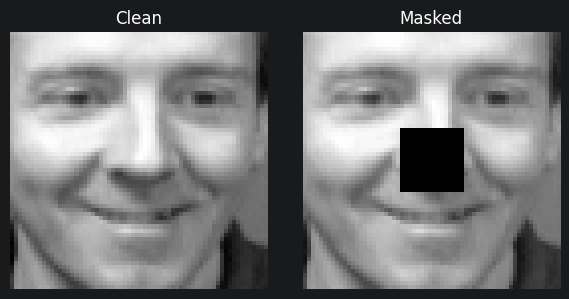

In [81]:

# Get predictions on clean and masked test images

clean_bag = predict_bagging(final_bagged_trees, X_test)
masked_bag = predict_bagging(final_bagged_trees, X_masked_test)

clean_samme = predict_samme(boostingModel, X_test)
masked_samme = predict_samme(boostingModel, X_masked_test)


# Find test images for which masking affects exactly one model
different_response = np.where(
    (clean_bag != masked_bag) !=
    (clean_samme != masked_samme)
)[0]

print("Candidate test indices:", different_response)

if len(different_response) > 0:
    idx = different_response[0]

    print("Test index:", idx)
    print("True identity:", y_test[idx])
    print("Bagging clean/masked:", clean_bag[idx], masked_bag[idx])
    print("SAMME clean/masked:", clean_samme[idx], masked_samme[idx])

    # Display the clean and masked images side by side
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))

    axes[0].imshow(X_test[idx].reshape(64, 64), cmap="gray")
    axes[0].set_title("Clean")

    axes[1].imshow(X_masked_test[idx].reshape(64, 64), cmap="gray")
    axes[1].set_title("Masked")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("No example found with this criterion.")
